## Dataset preparation

### Download the dataset: Amazon Berkeley Objects Dataset

In [1]:
# !wget https://amazon-berkeley-objects.s3.amazonaws.com/archives/abo-images-small.tar

In [2]:
# !tar -xvf ./abo-images-small.tar

### Unpack the dataset and locate the metadata file images.csv.gz in images/metadata/

In [3]:
# !gzip -d ./images/metadata/images.csv.gz

### Extract the image paths from the dataset:
- write a Python script that extracts valid image paths from the CSV file
- keep only images with at least 1000 pixels of width and height
- you can use Pandas, Polars etc. as you wish, add with uv whatever is necessary


In [30]:
import polars as pl

METADATA_PATH = "./images/metadata/images.csv"
metadata = pl.read_csv(METADATA_PATH)

In [31]:
metadata.describe()

statistic,image_id,height,width,path
str,str,f64,f64,str
"""count""","""398212""",398212.0,398212.0,"""398212"""
"""null_count""","""0""",0.0,0.0,"""0"""
"""mean""",null,1855.255645,1796.569488,null
"""std""",null,639.266192,609.717916,null
"""min""","""010-mllS7JL""",21.0,65.0,"""00/00000529.jpg"""
"""25%""",null,1315.0,1319.0,null
"""50%""",null,2200.0,1879.0,null
"""75%""",null,2400.0,2400.0,null
"""max""","""C1sCYAz8NAS""",2871.0,3000.0,"""ff/ffffe50e.jpg"""


In [32]:
import os

IMAGE_PATH = "./images/small"

def is_path_valid(path: str) -> bool:
    return os.path.isfile(path)

metadata = (
    metadata.with_columns(
        path=pl.lit(IMAGE_PATH + "/") + pl.col("path")
    )
    .filter(
        (pl.col("height") >= 1000)
        & (pl.col("width") >= 1000)
        & (pl.col("path").map_elements(is_path_valid))
    )
)

In [33]:
metadata.describe()

statistic,image_id,height,width,path
str,str,f64,f64,str
"""count""","""342878""",342878.0,342878.0,"""342878"""
"""null_count""","""0""",0.0,0.0,"""0"""
"""mean""",null,1987.289004,1904.428039,null
"""std""",null,529.19489,503.69754,null
"""min""","""21LlmxUCtTS""",1000.0,1000.0,"""./images/small/00/00000529.jpg"""
"""25%""",null,1500.0,1500.0,null
"""50%""",null,2200.0,1879.0,null
"""75%""",null,2508.0,2494.0,null
"""max""","""C1sCYAz8NAS""",2871.0,3000.0,"""./images/small/ff/ffffe50e.jpg"""


# Model Selection and Understanding 

### What is the vector size produced by clip-ViT-B-32?

512 (source: https://huggingface.co/sentence-transformers/clip-ViT-B-32/blob/main/0_CLIPModel/config.json)

### What do ViT, B and 32 mean in the model name?

- ViT stands for "Vision Transformer" which is an architecure based on transformer designed to process images
- B means "Base", so it's a standard model in its family
- 32 represents a 32 x 32 px patch size (the first step of that achitecture is to divide input image into non-overlapping patches)

# Database setup

### Set up Postgres database with pgvectorscale extension. You can reuse the database from the lab.

In [18]:
!docker compose up -d

[+] up 1/1
 ✔ Container vectorscaledb_homework Running                                 0.0s


### Use SQLAlchemy to connect to it with create_engine and URL.

In [19]:
from sqlalchemy.engine import URL
from sqlalchemy import create_engine

url = URL.create(
    drivername="postgresql",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db"
)

engine = create_engine(url)

### Create a database table definition for storing image embeddings. 

In [20]:
from sqlalchemy.orm import Mapped, mapped_column, DeclarativeBase
from pgvector.sqlalchemy import Vector
from sqlalchemy import String


class Base(DeclarativeBase):
    __abstract__ = True


class Img(Base):
    __tablename__ = "images"
    __table_args__ = {'extend_existing': True}
    
    VECTOR_LENGTH: int = 512
    
    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(255))
    embedding: Mapped[list[float]] = mapped_column(Vector(VECTOR_LENGTH))
    
# Create table
Base.metadata.create_all(engine)

# Image vectorization 

In [34]:
import joblib
import torch
from PIL import Image
from sentence_transformers import SentenceTransformer
from tqdm.notebook import tqdm
from itertools import batched
from sqlalchemy.orm import Session

MAX_IMAGES = None
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

model = SentenceTransformer('clip-ViT-B-32')

def insert_images(engine, images):
    with Session(engine) as session:
        session.add_all(images)
        session.commit()

def vectorize_images(engine, model, image_paths):    
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(image_paths, BATCH_SIZE):
            images = [Image.open(path) for path in images_paths_batch]
        
            # calculate embeddings
            embeddings = model.encode(images)
        
            # create Img instances for all images in batch
            imgs = [Img(image_path=path, embedding=embedding) for path, embedding in zip(images_paths_batch, embeddings)]

            # insert all batch images
            insert_images(engine, imgs)
        
            # update pbar
            pbar.update(len(imgs))

vectorize_images(engine, model, metadata["path"].to_list())

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

0it [00:00, ?it/s]

# Search and results display 

In [89]:
import matplotlib.pyplot as plt
from sqlalchemy import select, func

class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model
        
    def __call__(self, image_description: str, k: int, limit: int = None):
        if limit is None:
            found_images = self.find_similar_images(image_description, k)
        else:
            found_images = self.find_similar_images_with_limited_dataset(image_description, k, limit)
        # display images
        self.display_images(found_images, k)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = self.model.encode(image_description)
        
        # remember about session and commit
        query = (
            # write query to find K images with highest cosine distance
            select(Img)
            .order_by(Img.embedding.cosine_distance(image_embedding))
            .limit(k)
        )
        with Session(self.engine) as session:   
            result = session.execute(query).scalars().all()
        return result


    # This function is used to check if the results are better for larger datasets.
    def find_similar_images_with_limited_dataset(self, image_description: str, k: int, limit: int):
        image_embedding = self.model.encode(image_description)


        subset = (
            select(Img.id)
            .order_by(func.random())
            .limit(limit)
        )        
        query = (
            select(Img)
            .where(Img.id.in_(subset))
            .order_by(Img.embedding.cosine_distance(image_embedding))
            .limit(k)
        )
        with Session(self.engine) as session:
            result = session.execute(query).scalars().all()
        return result


    def display_images(self, images, k):
        fig, axes = plt.subplots(1, k, figsize=(15, 5))
        
        for i, image in enumerate(images):
            img_path = image.image_path
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i+1}")
        
        plt.show()

### Check a few different queries. Are results relevant?

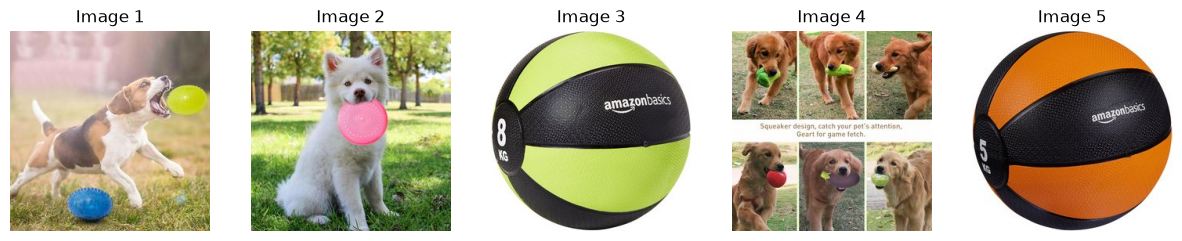

In [64]:
ImageSearch(engine, model)(
    "A large dog playing with a ball",
    k=5
)

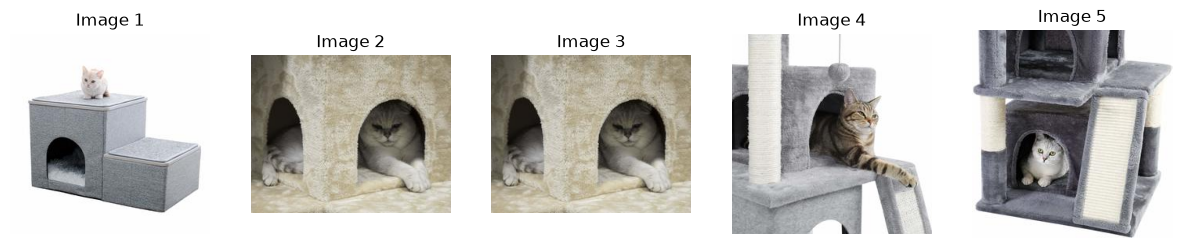

In [70]:
ImageSearch(engine, model)(
    "A king in his castle",
    k=5
)

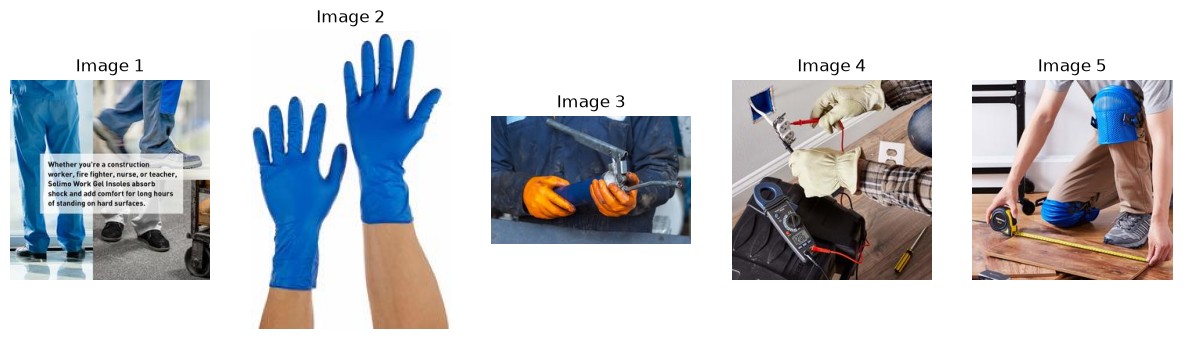

In [79]:
ImageSearch(engine, model)(
    "A hard working blue collar worker",
    k=5
)

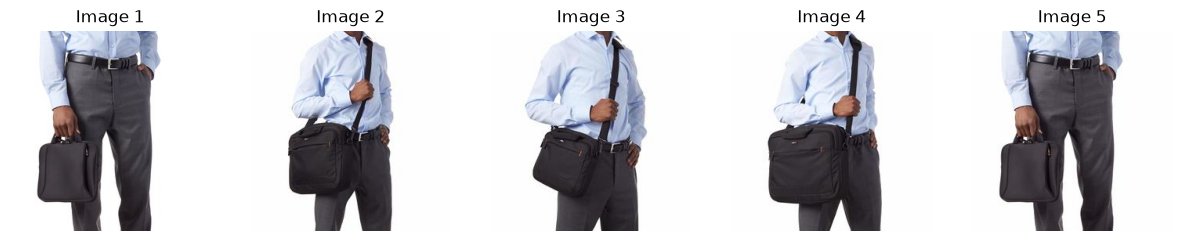

In [90]:
ImageSearch(engine, model)(
    "A hard working white collar worker",
    k=5
)

#### The results are actually quite accurate, though not perfect e.g. the query "A king in a castle" returned images of a cat in cat house which can be metaphorically interpreted as an exact result ;) The rest of the results are semantically correct, but the last one contains redundant images (they are technically distinct but very similar).

### Check 3 different MAX_IMAGES sizes. Do you see more accurate results for larger datasets?

##### I added optional param to ImageSearch to not process the dataset again

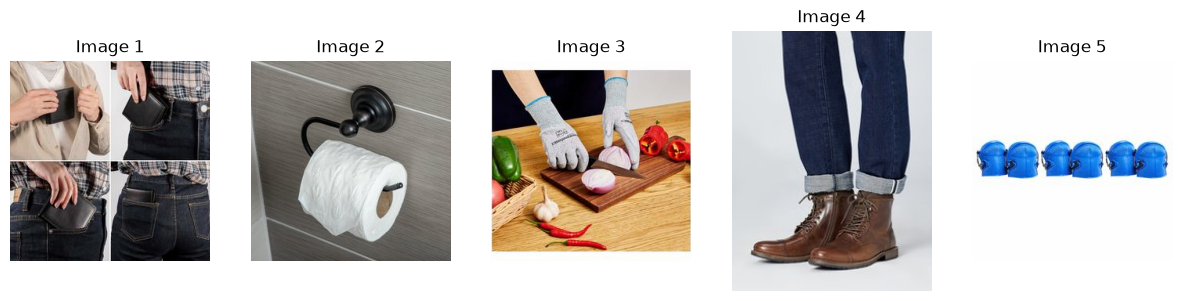

In [99]:
ImageSearch(engine, model)(
    "A hard working blue collar worker",
    k=5,
    limit=1000
)

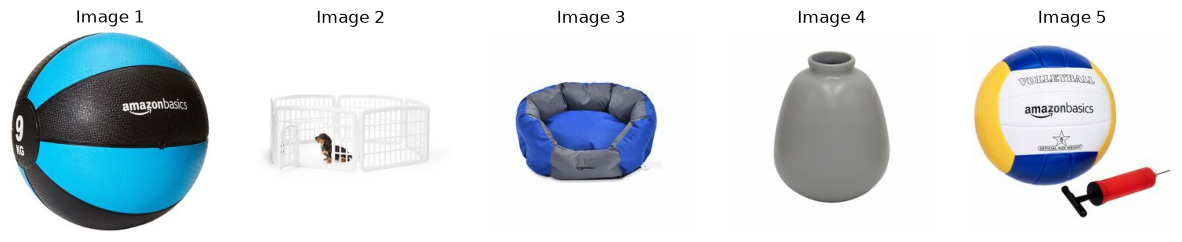

In [100]:
ImageSearch(engine, model)(
    "A large dog playing with a ball",
    k=5,
    limit=1000
)

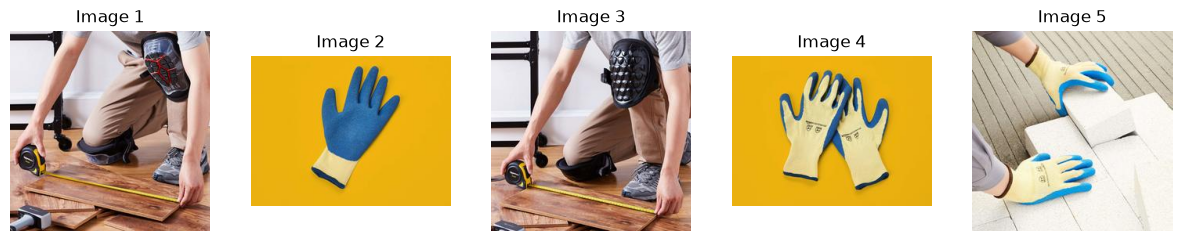

In [101]:
ImageSearch(engine, model)(
    "A hard working blue collar worker",
    k=5,
    limit=10000
)

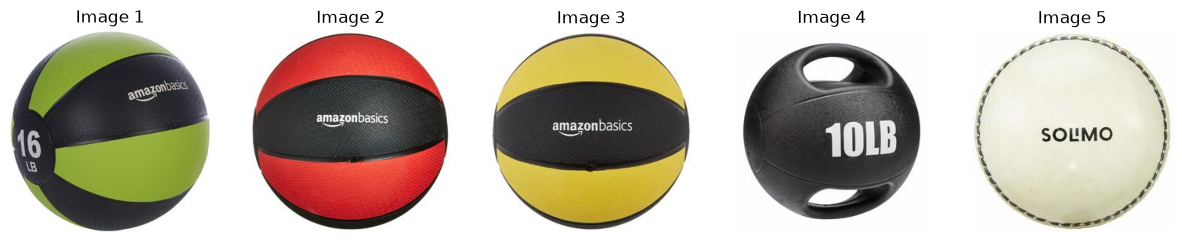

In [102]:
ImageSearch(engine, model)(
    "A large dog playing with a ball",
    k=5,
    limit=10000
)

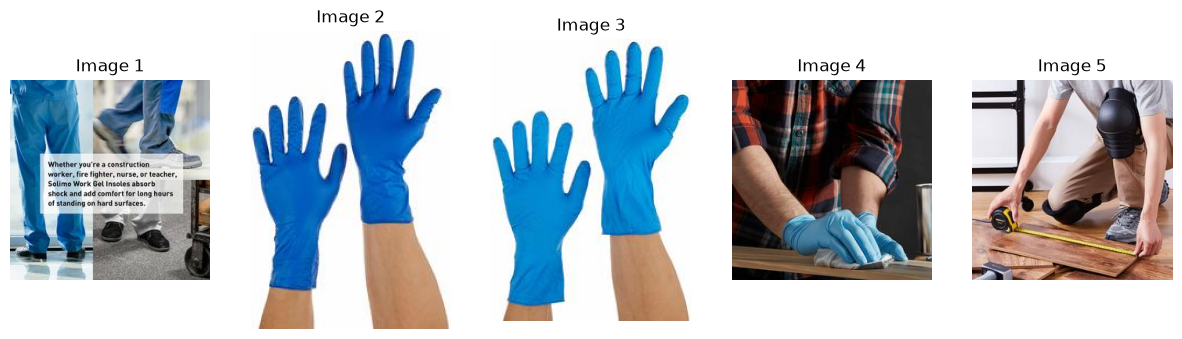

In [104]:
ImageSearch(engine, model)(
    "A hard working blue collar worker",
    k=5,
    limit=100000
)

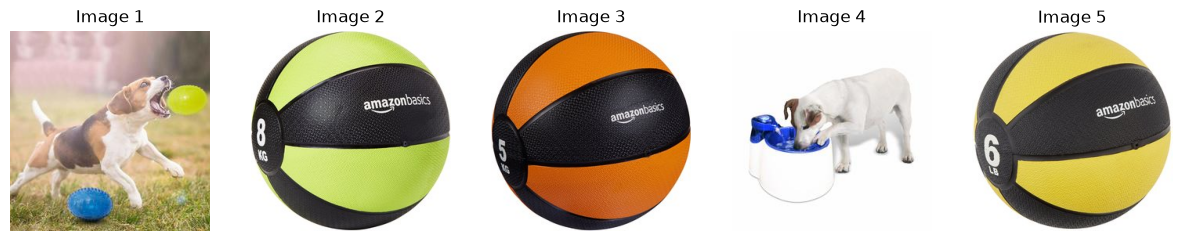

In [105]:
ImageSearch(engine, model)(
    "A large dog playing with a ball",
    k=5,
    limit=100000
)

#### As I expected, the results get worse with smaller datasets. For instance, a query "A hard working blue collar worker" on a dataset limited to 1000 examples did not even return the correct result. It's a standard behavior of vector databases (and retrieval systems in general), because having more candidates increases chances to get more samantically correct results.